# [Lab Session 2](otsu.ipynb)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

**[Task 1.1.]()** Load the image:

In [2]:
imgf = plt.imread("data/NIH3T3/im/dna-0.png")

**[Task 1.2.]()** Quantify the image into 256 bins:

In [3]:
img8 = (imgf * 255).round().astype(np.uint8)

**[Task 1.3.]()** Compute the image histogram:

In [4]:
h = np.zeros(256)

for i in range(256):
   count = np.sum(img8 == i)
   h[i] = count

Show the computed histogram:

In [5]:
plt.figure(figsize=(14,5))
plt.bar(range(256), h, width=1)

<BarContainer object of 256 artists>

**[Task 1.4.]()** Implement the method of Otsu:

In [8]:
T_min = np.full(256, np.inf)

for T in range(1,256):
    n1 = np.sum(h[:T])
    n2 = np.sum(h[T:])

    if n1 == 0 or n2 == 0:
        continue

    var1 = np.var(img8[img8 < T])
    var2 = np.var(img8[img8 >= T])

    T_min[T] = n1*var1 + n2*var2

T_star = np.argmin(T_min)
print(T_star)

31


**[Task 1.5.]()** Perform Otsu thresholding:

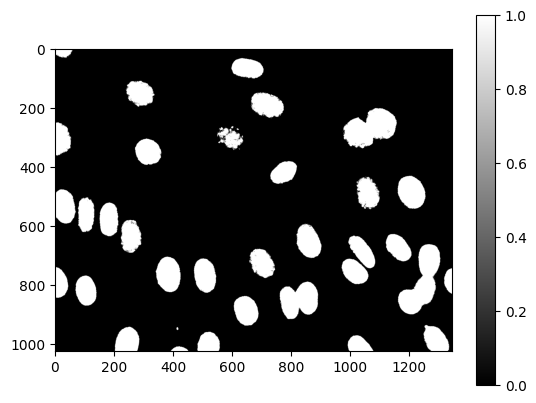

In [9]:
otsu_image = img8 >= T_star
plt.figure()
plt.imshow(otsu_image, cmap='gray')
plt.colorbar()
plt.show()


**[Task 1.6.]()** Compute the Dice coefficient:

In [ ]:
ground_truth = plt.imread("data/NIH3T3/gt/0.png")
ground_truth_bool = ground_truth == 1

G = otsu_image
H = ground_truth_bool

print(otsu_image.dtype)
print(ground_truth_bool.dtype)
print(G.shape)
print(H.shape)

dice = 2*(G*H).sum()/(G.sum()+H.sum())
print(dice)

bool
bool
(1024, 1344)
(1024, 1344)
0.8943783223933183
